# Electrodynamics from Scratch — Lecture 6: Quasi-Stationary Limit and the Biot–Savart Law

In Lecture 5 we assembled the Maxwell–Ampère law, $\nabla \times \mathbf{B} = \mu_0 \mathbf{J} + \mu_0 \epsilon_0\, \partial\mathbf{E}/\partial t$. This lecture works in the **quasi-stationary limit**: the currents vary so slowly that light crosses the whole circuit in a time $L/c$ far shorter than the variation timescale $1/\omega$. The displacement-current term $\mu_0 \epsilon_0\, \partial\mathbf{E}/\partial t$ is then negligible compared with $\mu_0 \mathbf{J}$, so magnetostatics applies at each instant, and the magnetic field of a steady current is given by the **Biot–Savart law**

$$\mathbf{B}(\mathbf{r}) = \frac{\mu_0 I}{4\pi} \oint \frac{d\boldsymbol{\ell}' \times (\mathbf{r} - \mathbf{r}')}{|\mathbf{r} - \mathbf{r}'|^3},$$

where the integral runs along the wire carrying the current $I$. Each current element $d\boldsymbol{\ell}'$ contributes a field perpendicular to both the element and the separation vector — unlike Coulomb's law, the source here is a *vector* (an oriented current element), not a scalar charge.

Two classic geometries follow by integration. For a long straight wire the field circles the wire and $|\mathbf{B}| = \mu_0 I/(2\pi r)$ falls off as $1/r$; for a circular loop of radius $a$ the field on the axis is $B_z = \mu_0 I a^2 / [2(a^2 + z^2)^{3/2}]$, largest at the centre. Stacking many loops into a long **solenoid** with $n$ turns per unit length gives an almost uniform interior field $\mathbf{B} \approx \mu_0 n I\, \hat{\mathbf{z}}$ — the standard way of producing a controlled field in the laboratory. The same fields come from the magnetic **vector potential**: $\mathbf{B} = \nabla \times \mathbf{A}$ with

$$\mathbf{A}(\mathbf{r}) = \frac{\mu_0 I}{4\pi} \oint \frac{d\boldsymbol{\ell}'}{|\mathbf{r} - \mathbf{r}'|}$$

in the Coulomb gauge.

In this notebook we compute all of these results numerically with `eds.biot_savart`, which discretizes the current into short polyline segments and sums the exact segment contributions. We verify the $1/r$ law of the straight wire with a log–log power-law fit, compare the loop against its analytic on-axis field, draw the loop's field lines in a plane containing its axis, probe the uniformity of the solenoid field, and check that the curl of the vector potential reproduces $\mathbf{B}$. Far from the loop we meet the $1/r^3$ dipole field, the bridge to the next lecture. All fields are in SI units (tesla).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

np.set_printoptions(precision=4, suppress=True)

## 1. A long straight wire: the $1/r$ law

We represent a wire along $z$ as a polyline of 200 segments extending from $z=-L$ to $z=+L$ with $L = 20$ m, and evaluate $\mathbf{B}$ at points a distance $r$ away in its midplane. Because the wire is much longer than any sampled distance ($r \le 2$ m), the numerical field should match $|B| = \mu_0 I/(2\pi r)$, and `eds.power_law_fit` should recover the exponent $-1$.

B at r = 1 m : [0. 0. 0.]   |B| = 1.815438110775402e-07
power-law fit : |B| = 1.9951e-07 * r^-1.0000
analytic 1/r amplitude  mu0*I/(2*pi) = 2.0000e-07


(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Long straight wire: |B| falls as 1/r'}, xlabel='r (m)', ylabel='|B| (T)'>)

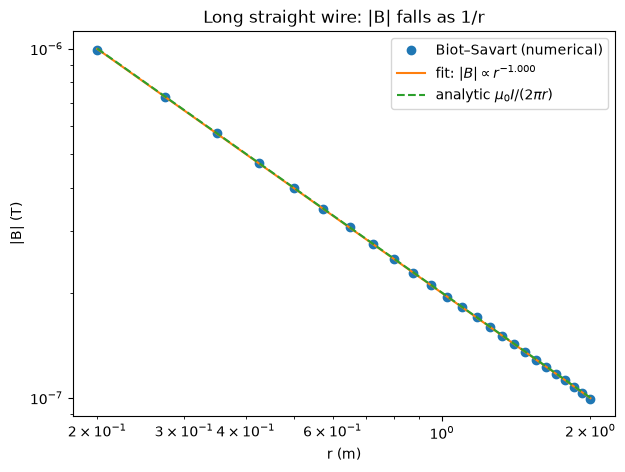

In [2]:
I = 1.0                      # current in amperes
L = 20.0                     # wire extends from z = -L to z = +L
n_segments = 200             # polyline segments (cheap)

z_vertices = np.linspace(-L, L, n_segments + 1)
wire = np.column_stack([np.zeros_like(z_vertices),
                        np.zeros_like(z_vertices),
                        z_vertices])

r = np.linspace(0.2, 2.0, 25)
points = np.column_stack([r, np.zeros_like(r), np.zeros_like(r)])
B = eds.biot_savart(wire, I, points)          # shape [N, 3], in tesla
B_mag = np.linalg.norm(B, axis=1)

# At (r, 0, 0) the field circles the wire: it should point along +y.
print("B at r = 1 m :", B[12], "  |B| =", B_mag[12])

amplitude, exponent = eds.power_law_fit(r, B_mag)
analytic_amp = eds.MU_0 * I / (2.0 * np.pi)
print(f"power-law fit : |B| = {amplitude:.4e} * r^{exponent:.4f}")
print(f"analytic 1/r amplitude  mu0*I/(2*pi) = {analytic_amp:.4e}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(r, B_mag, "o", label="Biot–Savart (numerical)")
ax.loglog(r, amplitude * r**exponent, "-",
          label=f"fit: $|B| \\propto r^{{{exponent:.3f}}}$")
ax.loglog(r, analytic_amp / r, "--", label=r"analytic $\mu_0 I/(2\pi r)$")
ax.set_xlabel("r (m)")
ax.set_ylabel("|B| (T)")
ax.set_title("Long straight wire: |B| falls as 1/r")
ax.legend()
fig, ax

## 2. Field on the axis of a circular loop

A loop of radius $a = 1$ m in the $xy$ plane carries a counter-clockwise current (as seen from $+z$), so its magnetic dipole moment points along $+z$. `eds.biot_savart` with `closed=True` closes the polyline into the loop; on the axis the result should match $B_z = \mu_0 I a^2\,/[2(a^2+z^2)^{3/2}]$, symmetric under $z \to -z$.

max relative error vs analytic on-axis field: 2.06e-04
dipole moment m = [0.     0.     3.1411]   (expected (0, 0, I*pi*a^2))


(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Field on the axis of a circular loop'}, xlabel='z (m)', ylabel='$B_z$ (T)'>)

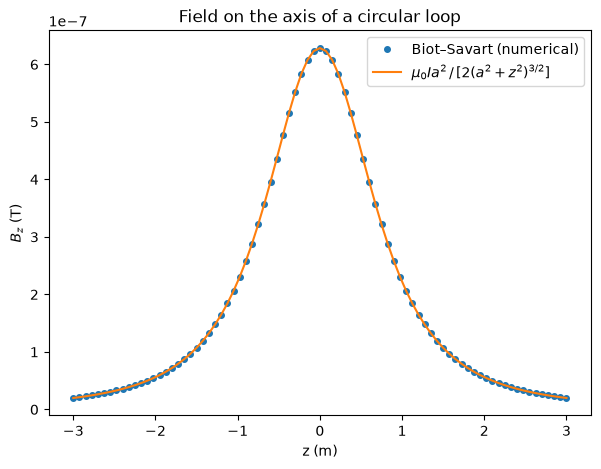

In [3]:
a = 1.0                      # loop radius in metres
I_loop = 1.0                 # current in amperes
loop = eds.circular_loop_curve(a, np.array([0.0, 0.0, 0.0]), n=200)

z = np.linspace(-3.0, 3.0, 81)
axis_points = np.column_stack([np.zeros_like(z), np.zeros_like(z), z])
B_axis = eds.biot_savart(loop, I_loop, axis_points, closed=True)
B_z = B_axis[:, 2]           # on the axis B points along z
B_analytic = eds.MU_0 * I_loop * a**2 / (2.0 * (a**2 + z**2)**1.5)

rel_err = np.max(np.abs(B_z - B_analytic)) / np.max(np.abs(B_analytic))
print(f"max relative error vs analytic on-axis field: {rel_err:.2e}")

m = eds.magnetic_dipole_moment(loop, I_loop, closed=True)
print("dipole moment m =", m, "  (expected (0, 0, I*pi*a^2))")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(z, B_z, "o", ms=4, label="Biot–Savart (numerical)")
ax.plot(z, B_analytic, "-", label=r"$\mu_0 I a^2\,/\,[2(a^2+z^2)^{3/2}]$")
ax.set_xlabel("z (m)")
ax.set_ylabel(r"$B_z$ (T)")
ax.set_title("Field on the axis of a circular loop")
ax.legend()
fig, ax

## 3. Field lines of the loop in a plane through its axis

The field lines of the loop close through its interior and return far outside — the familiar dipole pattern. `eds.plot_field_lines` samples a `field_func(X, Y)` on a 2D mesh, so we build one that maps the horizontal mesh coordinate to the radial direction $x$ and the vertical one to $z$, evaluating the loop field in the $y = 0$ plane.

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Field lines of a current loop (x–z plane; color: $\\log_{10}|B|$)'}, xlabel='x (m)', ylabel='y (m)'>)

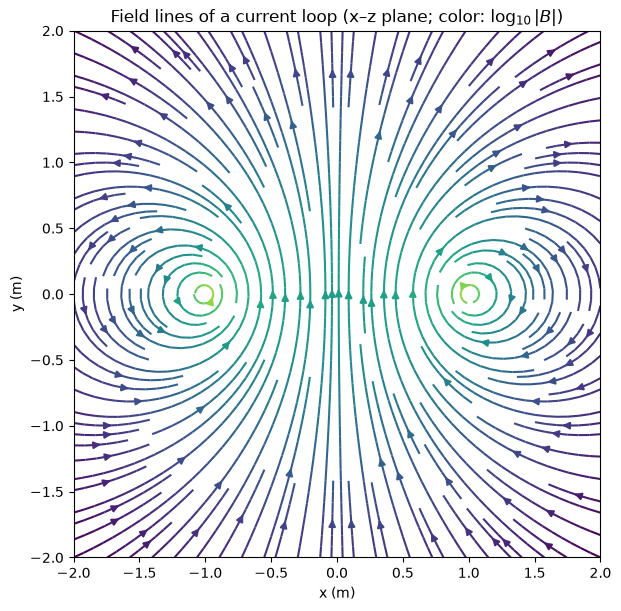

In [4]:
def loop_field_xz(X, Y):
    """B of the loop in the x-z plane: plot-x = x, plot-y = z."""
    pts = np.column_stack([X.ravel(), np.zeros(X.size), Y.ravel()])
    B = eds.biot_savart(loop, I_loop, pts, closed=True)
    return B[:, 0].reshape(X.shape), B[:, 2].reshape(X.shape)

fig, ax = eds.plot_field_lines(
    loop_field_xz,
    extent=2.0,
    density=1.6,
    title="Field lines of a current loop (x–z plane; color: $\\log_{10}|B|$)",
)
fig, ax

## 4. The solenoid: a nearly uniform interior field

A solenoid is a helical winding along $z$; `eds.solenoid_curve` builds one with 10 turns over a length of 4 m, i.e. $n = 2.5$ turns per metre. Inside a long solenoid the contributions of the individual turns add up to an almost uniform field $\mathbf{B} \approx \mu_0 n I\, \hat{\mathbf{z}}$, which drops sharply outside the ends.

turns per unit length n = 2.50 /m;  mu0*n*I = 3.142e-06 T
midplane |B|: min = 3.054e-06 T, max = 3.249e-06 T, variation = 5.99%


(<Figure size 1100x450 with 2 Axes>,
 array([<Axes: title={'center': '|B| along the solenoid axis'}, xlabel='z (m)', ylabel='|B| (T)'>,
        <Axes: title={'center': '|B| across the midplane (z = 2 m)'}, xlabel='radial distance $\\rho$ (m)', ylabel='|B| (T)'>],
       dtype=object))

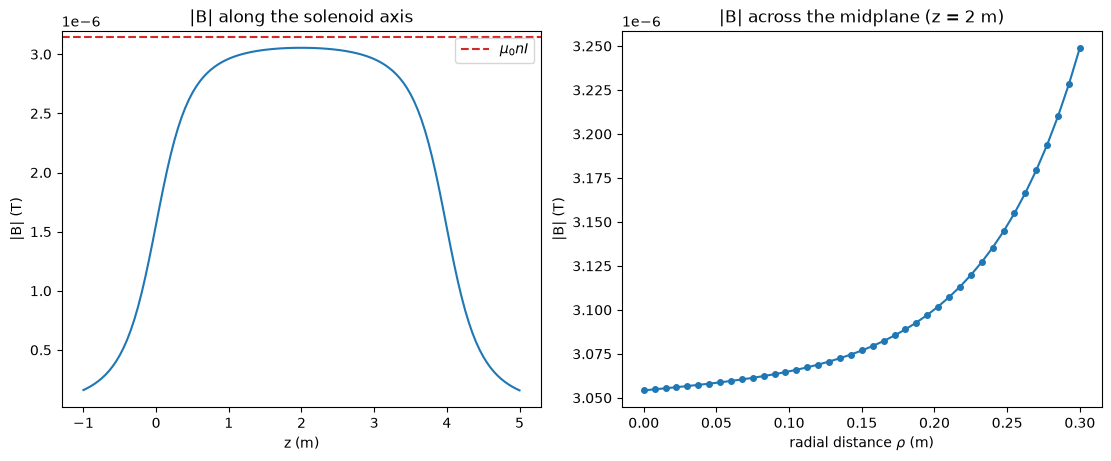

In [5]:
R_sol, length, turns = 0.5, 4.0, 10
solenoid = eds.solenoid_curve(R_sol, length, turns, n_per_turn=40)
n_turns_per_m = turns / length
B_uniform = eds.MU_0 * n_turns_per_m * I
print(f"turns per unit length n = {n_turns_per_m:.2f} /m;"
      f"  mu0*n*I = {B_uniform:.3e} T")

# (a) field along the axis, from outside one end to outside the other
z_ax = np.linspace(-1.0, 5.0, 121)
ax_pts = np.column_stack([np.zeros_like(z_ax), np.zeros_like(z_ax), z_ax])
B_ax = eds.biot_savart(solenoid, I, ax_pts)

# (b) field across a radius in the midplane z = length/2, over the
#     bore of the solenoid (very close to the winding at rho = R_sol
#     the field of the individual wire takes over instead)
rho = np.linspace(0.0, 0.3, 41)
mid_pts = np.column_stack([rho, np.zeros_like(rho),
                           np.full_like(rho, length / 2.0)])
B_mid_mag = np.linalg.norm(eds.biot_savart(solenoid, I, mid_pts), axis=1)
spread = 100.0 * (B_mid_mag.max() - B_mid_mag.min()) / B_mid_mag.max()
print(f"midplane |B|: min = {B_mid_mag.min():.3e} T,"
      f" max = {B_mid_mag.max():.3e} T, variation = {spread:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
axes[0].plot(z_ax, np.linalg.norm(B_ax, axis=1))
axes[0].axhline(B_uniform, ls="--", color="tab:red", label=r"$\mu_0 n I$")
axes[0].set_xlabel("z (m)")
axes[0].set_ylabel("|B| (T)")
axes[0].set_title("|B| along the solenoid axis")
axes[0].legend()
axes[1].plot(rho, B_mid_mag, "o-", ms=4)
axes[1].set_xlabel(r"radial distance $\rho$ (m)")
axes[1].set_ylabel("|B| (T)")
axes[1].set_title("|B| across the midplane (z = 2 m)")
fig, axes

## 5. The vector potential and $\mathbf{B} = \nabla \times \mathbf{A}$

The loop's vector potential in the Coulomb gauge is returned by `eds.vector_potential_wire`. In the midplane of an axisymmetric loop $\mathbf{A}$ points along $\hat{\boldsymbol{\phi}}$, and the $z$-component of the field follows from $B_z = (1/\rho)\, d(\rho A_\phi)/d\rho$. We check that finite differences of $A_\phi$ reproduce `eds.biot_savart` directly.

max relative difference  curl(A) vs Biot–Savart: 3.10e-03


(<Figure size 1100x450 with 2 Axes>,
 array([<Axes: title={'center': 'Vector potential of the loop (midplane)'}, xlabel='$\\rho$ (m)', ylabel='$A_\\phi$ (T m)'>,
        <Axes: title={'center': '$B_z = $ curl of $A$ vs direct integration'}, xlabel='$\\rho$ (m)', ylabel='$B_z$ (T)'>],
       dtype=object))

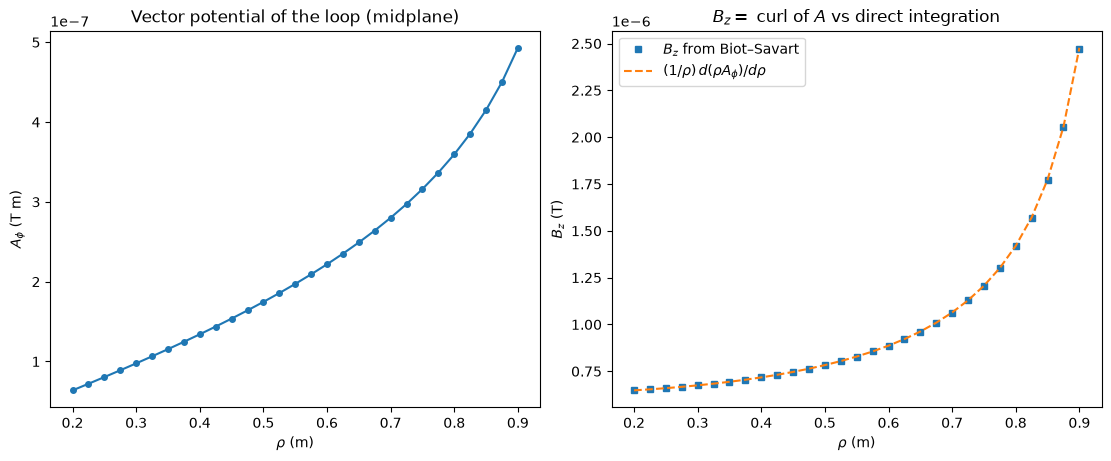

In [6]:
h = 0.01                     # step for the finite difference
rho = np.linspace(0.2, 0.9, 29)   # inside the loop, clear of the wire

def A_phi(rho_vals):
    """A of the loop in the midplane; at (rho, 0, 0) phi-hat = +y."""
    pts = np.column_stack([rho_vals, np.zeros_like(rho_vals),
                           np.zeros_like(rho_vals)])
    return eds.vector_potential_wire(loop, I_loop, pts, closed=True)[:, 1]

A_mid = A_phi(rho)
B_from_A = ((rho + h) * A_phi(rho + h)
            - (rho - h) * A_phi(rho - h)) / (2.0 * h * rho)
B_direct = eds.biot_savart(
    loop, I_loop,
    np.column_stack([rho, np.zeros_like(rho), np.zeros_like(rho)]),
    closed=True)[:, 2]

err = np.max(np.abs(B_from_A - B_direct)) / np.max(np.abs(B_direct))
print(f"max relative difference  curl(A) vs Biot–Savart: {err:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
axes[0].plot(rho, A_mid, "o-", ms=4)
axes[0].set_xlabel(r"$\rho$ (m)")
axes[0].set_ylabel(r"$A_\phi$ (T m)")
axes[0].set_title("Vector potential of the loop (midplane)")
axes[1].plot(rho, B_direct, "s", ms=5, label=r"$B_z$ from Biot–Savart")
axes[1].plot(rho, B_from_A, "--",
             label=r"$(1/\rho)\, d(\rho A_\phi)/d\rho$")
axes[1].set_xlabel(r"$\rho$ (m)")
axes[1].set_ylabel(r"$B_z$ (T)")
axes[1].set_title(r"$B_z = $ curl of $A$ vs direct integration")
axes[1].legend()
fig, axes

## 6. Far from the loop: the dipole field

At distances large compared with $a$ the loop's field approaches that of a point magnetic dipole $\mathbf{m} = I \pi a^2\, \hat{\mathbf{z}}$, with $|\mathbf{B}|$ decaying as $1/r^3$ along the axis. `eds.magnetic_dipole_moment` extracts $\mathbf{m}$ from the loop, `eds.magnetic_dipole_field` evaluates its exact dipole field, and a power-law fit confirms the exponent $-3$ — the bridge to the next lecture on magnetic dipoles.

dipole moment m = [0.     0.     3.1411]
far-field fit: |B| = 5.598e-07 * r^-2.958   (dipole: exponent -3)


(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'On-axis |B|: current loop vs point dipole'}, xlabel='r (m)', ylabel='field / potential strength'>)

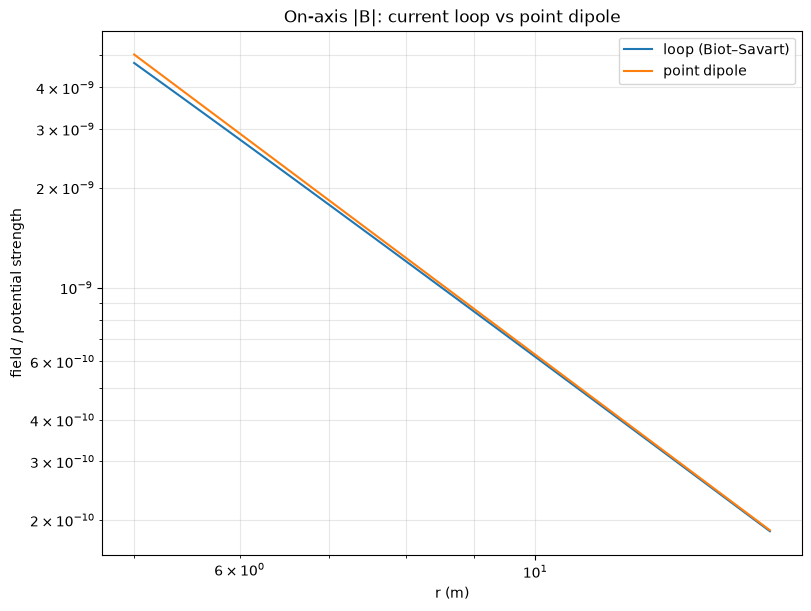

In [7]:
m = eds.magnetic_dipole_moment(loop, I_loop, closed=True)
print("dipole moment m =", m)

r_far = np.linspace(5.0, 15.0, 25)     # far compared with a = 1 m
far_points = np.column_stack([np.zeros_like(r_far),
                              np.zeros_like(r_far),
                              r_far])          # along the dipole axis
B_far = np.linalg.norm(
    eds.biot_savart(loop, I_loop, far_points, closed=True), axis=1)
B_dip = np.linalg.norm(eds.magnetic_dipole_field(m, far_points), axis=1)

amp, expo = eds.power_law_fit(r_far, B_far)
print(f"far-field fit: |B| = {amp:.3e} * r^{expo:.3f}   (dipole: exponent -3)")

fig, ax = eds.plot_decay(
    r_far,
    {"loop (Biot–Savart)": B_far, "point dipole": B_dip},
    title="On-axis |B|: current loop vs point dipole",
)
fig, ax

## Exercises

1. **Quasi-static criterion.** The Biot–Savart law is instantaneous: it ignores the light travel time between the wire and the field point. Estimate the largest frequency $\omega$ at which a device of size $L = 1$ m can still be treated quasi-statically, and explain what must replace the Biot–Savart law once $\omega L / c \gtrsim 1$.

2. **Edge effects in the straight wire.** Repeat the fit of Section 1 with a much shorter wire, $L = 2$ m, keeping the same range of $r$. The fitted exponent should deviate from $-1$. Use the exact finite-wire result $|B| = (\mu_0 I / 2\pi r)\cdot L/\sqrt{L^2 + r^2}$ to predict the deviation, then restore the exponent $-1$ by increasing $L$.

3. **Reversing the current.** Re-run Section 2 with the current reversed (pass $-I\_loop$ to `eds.biot_savart`, or reverse the vertex order of `loop`). Confirm that $B_z$ and `eds.magnetic_dipole_moment` both change sign, and relate this to the right-hand rule.

4. **A charge in the solenoid field.** Use `eds.biot_savart` with the solenoid from Section 4 to get $\mathbf{B}$ at its centre, then `eds.lorentz_force` to compute the force on a charge $q = $ `eds.ELEMENTARY_CHARGE` moving with $\mathbf{v} = (0,\ 10^6,\ 0)$ m/s. Verify $|\mathbf{F}| = |q|\, v\, B$ and use $r = m v/(|q| B)$ to estimate the radius of the resulting circular motion.

5. **Why the solenoid field is uniform.** Use Ampère's law, $\oint \mathbf{B}\cdot d\boldsymbol{\ell} = \mu_0 I_{\text{enc}}$, applied to a rectangular loop piercing the solenoid wall, to argue that $B = \mu_0 n I$ inside a long solenoid and $B = 0$ outside. Where does the argument fail near the ends, and how is that visible in the left panel of Section 4?

6. **Field lines of the solenoid.** Following the pattern of `loop_field_xz` in Section 3, define a `field_func` for the solenoid and draw its field lines in the $x$–$z$ plane with `eds.plot_field_lines`. Where do the lines close, and how does the pattern change if you double the number of turns at fixed length?